In [2]:
!pip install sidetable
!conda install -c conda-forge --yes scienceplots

Channels:
 - conda-forge
 - defaults
Platform: osx-arm64
Solving environment: done

# All requested packages already installed.



In [2]:
import os
from configparser import ConfigParser
from matplotlib import pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import scienceplots
import seaborn as sns
import sidetable

In [3]:
plt.style.use('science')

In [4]:
os.getcwd()

'/Users/janik/source/urban-mobility-simulation/resources/scripts/simulation_analysis'

In [5]:
os.chdir("../../../")
os.getcwd()

'/Users/janik/source/urban-mobility-simulation'

In [6]:
from simulation.helper.time import SimulationTimeConverter

In [7]:
# Read args
parser = ConfigParser()
parser.read("resources/configurations/shared-charging.ini")

['resources/configurations/shared-charging.ini']

In [70]:
auction_tracking = pd.read_csv("data/output/tracking/auction.csv")

In [71]:
auction_tracking

,time,participant_id,location,_bids,_result
0,105,0,872664c1affffff,"[(3, 0.0, 0), (1, 0.8198392054513413, 0), (1, ...","(10, 0.0)"
1,120,0,872664c13ffffff,[],"(10, 0.0)"
2,120,1,872664c1effffff,"[(3, 0.0, 1), (1, 1.772959743226822, 1), (1, 2...","(10, 0.0)"
3,135,1,872664cadffffff,"[(3, 0.0, 1), (1, 1.2711795144720877, 1), (1, ...","(10, 0.0)"
4,150,1,872664cacffffff,"[(3, 0.0, 1), (1, 1.2711795144720877, 1), (1, ...","(10, 0.0)"
5,210,0,872664cacffffff,"[(9, 0.0, 0)]","(1, 2.5142944865338768)"
6,210,1,872664cacffffff,"[(4, 0.0, 1), (1, 1.7741760898187335, 1), (1, ...","(9, 2.5142944865338768)"
7,270,0,872664cacffffff,"[(4, 0.0, 0), (1, 0.6975306147362161, 0), (1, ...","(2, 2.9094951411747787)"
8,270,1,872664cacffffff,"[(4, 0.0, 1), (1, 0.6975306147362161, 1), (1, ...","(8, 2.9094951411747787)"
9,300,0,872664c1effffff,"[(3, 0.0, 0), (1, 1.7741760898187335, 0), (1, ...","(5, 2.9031730333533763)"


In [72]:
# rename time axis
auction_tracking['timestamp'] = pd.to_datetime(auction_tracking['time'].apply(SimulationTimeConverter.as_time), format="%H:%M:%S")

In [73]:
auction_tracking['_result.clearing_price'] = auction_tracking['_result'].apply(lambda x: eval(x)[1])
auction_tracking['_result.capacity'] = auction_tracking['_result'].apply(lambda x: eval(x)[0])

auction_tracking['_bids.total_capacity'] = auction_tracking['_bids'].apply(lambda x: sum([b[0] for b in eval(x)]))
auction_tracking['_bids.mean_bid'] = auction_tracking['_bids'].apply(lambda x: np.mean([b[1] for b in eval(x)]))

/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [74]:
auction_tracking

,time,participant_id,location,_bids,_result,timestamp,_result.clearing_price,_result.capacity,_bids.total_capacity,_bids.mean_bid
0,105,0,872664c1affffff,"[(3, 0.0, 0), (1, 0.8198392054513413, 0), (1, ...","(10, 0.0)",1900-01-01 01:45:00,0.000000,10,9,2.686806
1,120,0,872664c13ffffff,[],"(10, 0.0)",1900-01-01 02:00:00,0.000000,10,0,NaN
2,120,1,872664c1effffff,"[(3, 0.0, 1), (1, 1.772959743226822, 1), (1, 2...","(10, 0.0)",1900-01-01 02:00:00,0.000000,10,9,2.700951
3,135,1,872664cadffffff,"[(3, 0.0, 1), (1, 1.2711795144720877, 1), (1, ...","(10, 0.0)",1900-01-01 02:15:00,0.000000,10,9,2.268580
4,150,1,872664cacffffff,"[(3, 0.0, 1), (1, 1.2711795144720877, 1), (1, ...","(10, 0.0)",1900-01-01 02:30:00,0.000000,10,9,2.268580
5,210,0,872664cacffffff,"[(9, 0.0, 0)]","(1, 2.5142944865338768)",1900-01-01 03:30:00,2.514294,1,9,0.000000
6,210,1,872664cacffffff,"[(4, 0.0, 1), (1, 1.7741760898187335, 1), (1, ...","(9, 2.5142944865338768)",1900-01-01 03:30:00,2.514294,9,9,2.294873
7,270,0,872664cacffffff,"[(4, 0.0, 0), (1, 0.6975306147362161, 0), (1, ...","(2, 2.9094951411747787)",1900-01-01 04:30:00,2.909495,2,9,1.338908
8,270,1,872664cacffffff,"[(4, 0.0, 1), (1, 0.6975306147362161, 1), (1, ...","(8, 2.9094951411747787)",1900-01-01 04:30:00,2.909495,8,9,1.338908
9,300,0,872664c1effffff,"[(3, 0.0, 0), (1, 1.7741760898187335, 0), (1, ...","(5, 2.9031730333533763)",1900-01-01 05:00:00,2.903173,5,9,2.540166


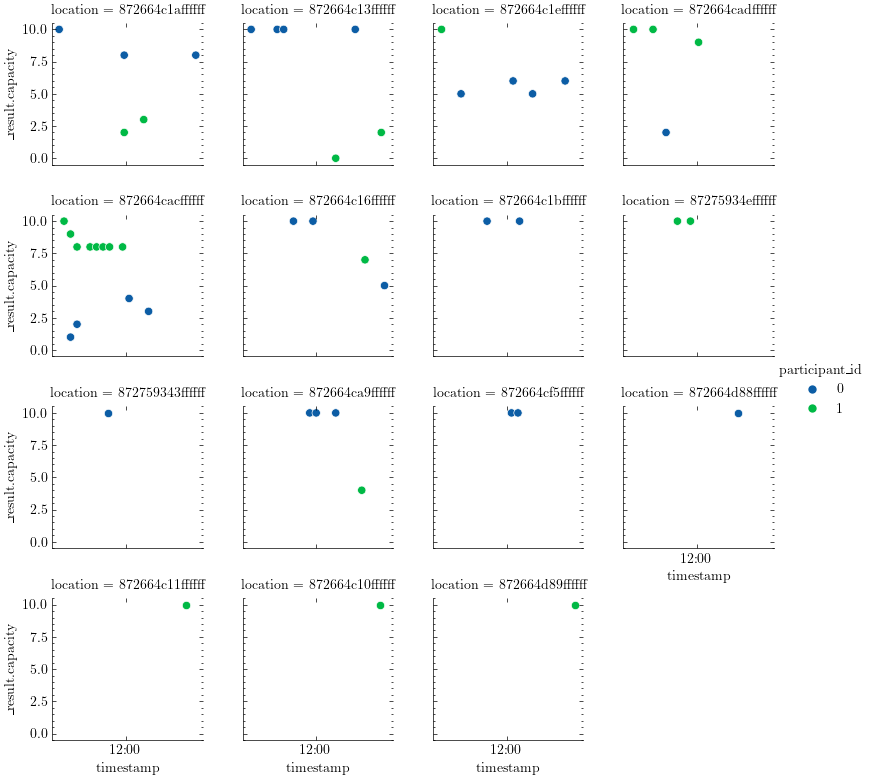

In [75]:
auction_tracking.sort_values(by=['time', 'location'], inplace=True)
g = sns.relplot(data=auction_tracking, x="timestamp", y="_result.capacity", hue="participant_id", col="location", col_wrap=4, kind="scatter", height=2)

axes = g.axes.flat

for a in axes:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=4))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

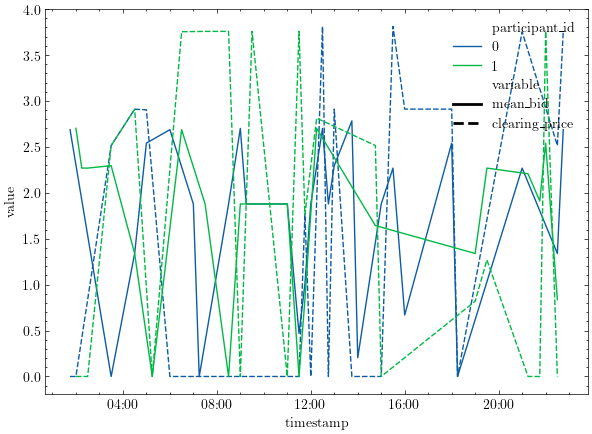

In [76]:
from matplotlib.lines import Line2D


fig, ax = plt.subplots(1,1, figsize=(7,5))

auction_tracking_long = auction_tracking.melt(id_vars=['timestamp', 'location', 'participant_id'], value_vars=['_result.clearing_price', '_bids.mean_bid'])
auction_tracking_long['variable'] = auction_tracking_long['variable'].astype('category')

sns.lineplot(data=auction_tracking_long, x="timestamp", y="value", hue="participant_id", style="variable", ax=ax)

handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([0], [0], color='black', lw=2, linestyle='solid'))
handles.append(Line2D([0], [0], color='black', lw=2, linestyle='dashed'))
labels.extend(['mean_bid', 'clearing_price'])

ax.legend(handles=handles, labels=labels)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=8))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

## Vehicles

In [77]:
vehicle_tracking = pd.read_csv("data/output/tracking/vehicles.csv")

In [78]:
vehicle_tracking['_state'].apply(lambda x: set(eval(x))).value_counts()

_state
{1, 2, 3, 4, 1003}             1166
{1, 2, 3, 4, 1001, 1003}       1039
{1, 2, 3, 4, 5, 1003}           135
{1, 2, 3, 4, 5, 1001, 1003}     107
{1, 2, 3, 4}                    106
{1, 2, 1003}                     83
{1, 2}                           65
{1, 2, 3, 4, 1001}               62
{1, 2, 1001}                     40
{1, 2, 1003, 1001}               27
{1, 2, 3, 4, 5, 1001}            14
{1, 2, 3, 4, 5}                  11
{1}                               8
{1, 2, 3, 1003}                   7
{1, 1001}                         2
{1, 2, 3, 1001}                   2
{1, 2, 3}                         2
{1, 2, 3, 1001, 1003}             2
Name: count, dtype: int64

In [79]:
RECHARGE_THRESHOLD = 25 # ATTENTION: This is an approximation, we use dynamic ones per base region

vehicle_tracking['fleet_average_SOC'] = vehicle_tracking['_current_state_of_charge'].apply(lambda x: np.mean(eval(x)))
vehicle_tracking['fleet_number_low_SOC'] = vehicle_tracking['_current_state_of_charge'].apply(lambda x: np.count_nonzero(np.array(eval(x))< RECHARGE_THRESHOLD))

In [80]:
# rename time axis
vehicle_tracking['time'] = pd.to_datetime(vehicle_tracking['time'].apply(SimulationTimeConverter.as_time), format="%H:%M:%S")

vehicle_tracking['timestamp'] = vehicle_tracking['time'].dt.strftime("%H:%M")

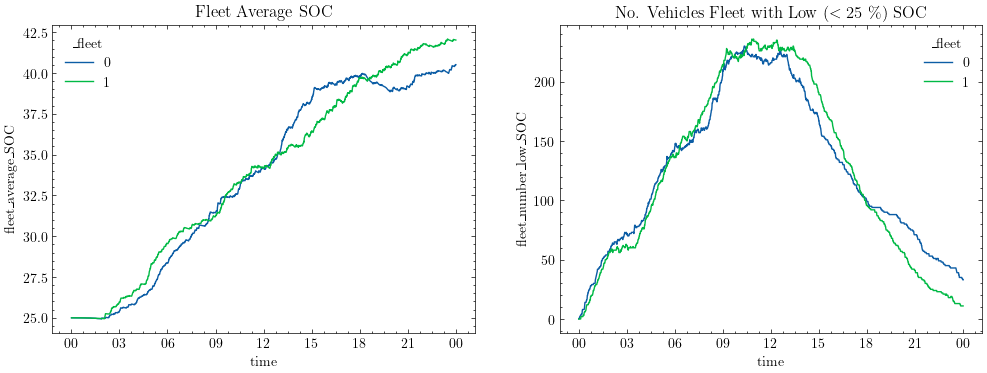

In [81]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (12, 4))

sns.lineplot(data=vehicle_tracking, x='time', y='fleet_average_SOC', hue='_fleet', ax = ax[0])
sns.lineplot(data=vehicle_tracking, x='time', y='fleet_number_low_SOC', hue='_fleet', ax = ax[1])

ax[0].set_title('Fleet Average SOC')
ax[1].set_title(f'No. Vehicles Fleet with Low ($< {RECHARGE_THRESHOLD}$ \%) SOC')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

In [82]:
INITIALIZED = 0
PARKING = 1
DRIVING = 2
RELOCATING = 3
CHARGING = 4
PRE_SERVICE = 5
ONLINE = 6  # When the driver is online
OFFLINE = 7  # When the driver is offline
SOME_STATE = 1002
RESERVED = 1001
MOVING_TO_PICK_UP_POS = 1003

In [83]:
vehicle_tracking['_state_PARKING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PARKING))

vehicle_tracking['_state_CHARGING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == CHARGING))

vehicle_tracking['_state_DRIVING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == DRIVING))

vehicle_tracking['_state_RELOCATING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RELOCATING))

vehicle_tracking['_state_PRE_SERVICE'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PRE_SERVICE))

vehicle_tracking['_state_MOVING_TO_PICK_UP_POS'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == MOVING_TO_PICK_UP_POS))

vehicle_tracking['_state_RESERVED'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RESERVED))

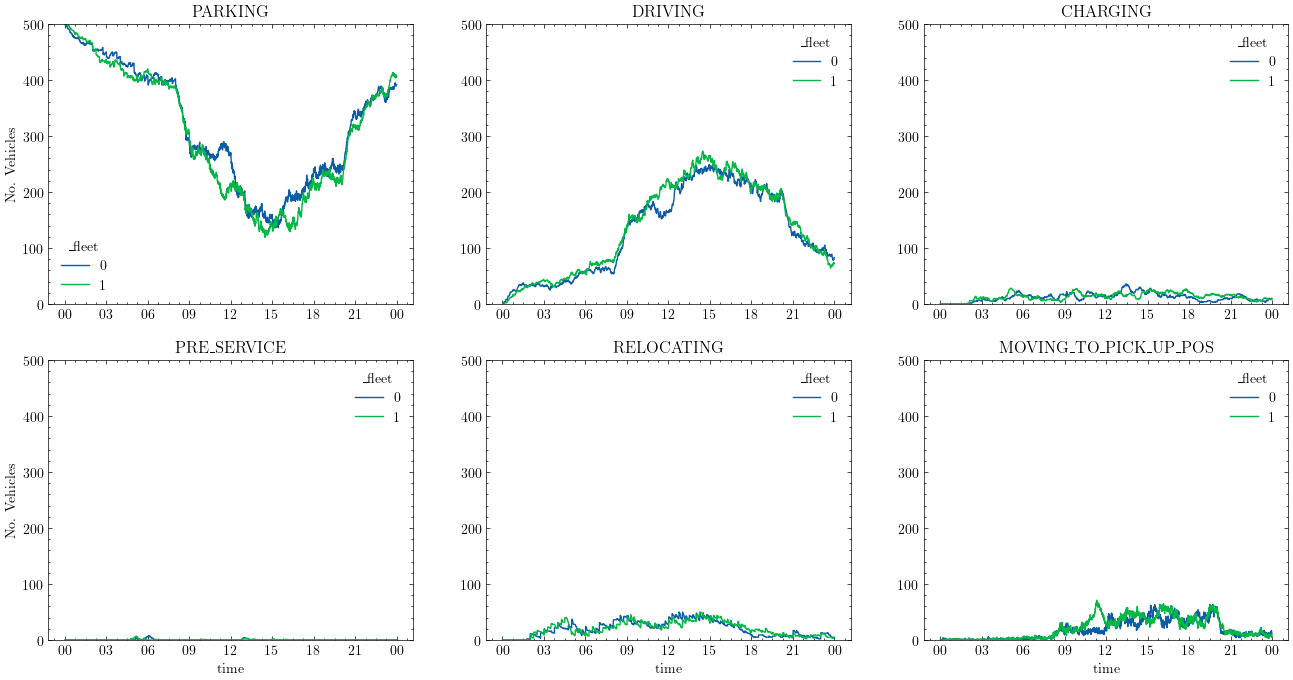

In [84]:
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(16, 8))
sns.lineplot(data=vehicle_tracking, x='time', y='_state_PARKING', hue='_fleet', ax=ax[0][0])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_DRIVING', hue='_fleet', ax=ax[0][1])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_CHARGING', hue='_fleet', ax=ax[0][2])

sns.lineplot(data=vehicle_tracking, x='time', y='_state_PRE_SERVICE', hue='_fleet', ax=ax[1][0])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_RELOCATING', hue='_fleet', ax=ax[1][1])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_MOVING_TO_PICK_UP_POS', hue='_fleet', ax=ax[1][2])

ax[0][0].set_title('PARKING')
ax[0][1].set_title('DRIVING')
ax[0][2].set_title('CHARGING')

ax[1][0].set_title('PRE_SERVICE')
ax[1][1].set_title('RELOCATING')
ax[1][2].set_title('MOVING_TO_PICK_UP_POS')


for aa in ax:
    for i, a in enumerate(aa):
        a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
        a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))


        a.set_ylabel('No. Vehicles')
        a.set_ylim(0, parser.getint("EXPERIMENT_MANAGEMENT", "N_CARS"))
        a.yaxis.label.set_visible(False) if i > 0 else None

for a in ax[0]:
    a.xaxis.label.set_visible(False)

## Charging Stations

In [85]:
charging_station_tracking = pd.read_csv("data/output/tracking/charging_stations.csv")

In [86]:
CHARGING_STATION_CAPACITY = parser.getint("CHARGING_INFRASTRUCTURE", "CHARGING_STATION_CAPACITY")

In [87]:
charging_station_tracking['utilization'] = charging_station_tracking['_plugs.count'] / CHARGING_STATION_CAPACITY

charging_station_tracking['system_wide_utilization'] = charging_station_tracking.groupby('time')['utilization'].transform('mean')

In [88]:
# rename time axis
charging_station_tracking['time'] = pd.to_datetime(charging_station_tracking['time'].apply(SimulationTimeConverter.as_time), format="%H:%M:%S")

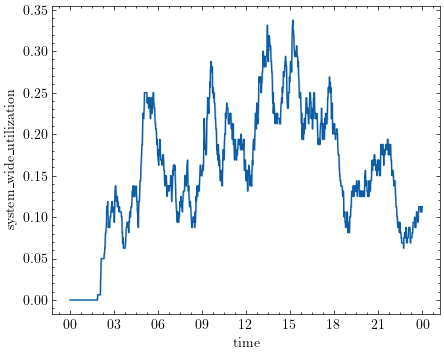

In [89]:
fig, ax = plt.subplots(1,1, figsize=(5,4))

sns.lineplot(data=charging_station_tracking, x='time', y='system_wide_utilization', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

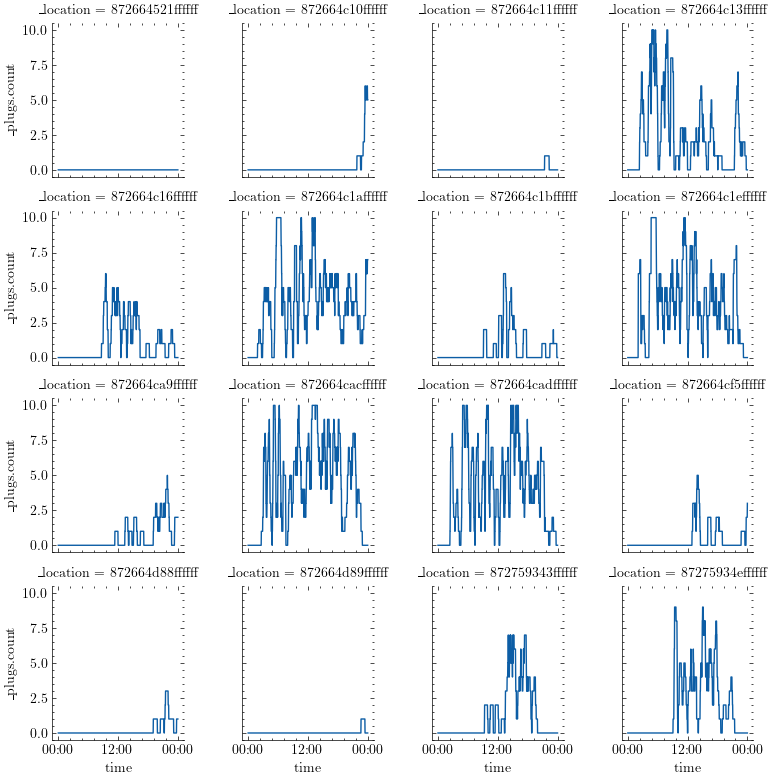

In [90]:
charging_station_tracking.sort_values(by=['time', '_location'], inplace=True)
g = sns.relplot(
    data=charging_station_tracking, x='time', y='_plugs.count', col='_location', kind='line', col_wrap=4, height=2)

axes = g.axes.flat

for a in axes:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=4))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

## Transactions

In [91]:
transactions_fleet_0 = pd.read_csv("data/output/transactions/fleet_0_transactions.csv")
transactions_fleet_1 = pd.read_csv("data/output/transactions/fleet_1_transactions.csv")

In [92]:
RESAMPLE_RATE = '1h'

In [93]:
transactions_fleet_0['timestamp'] = transactions_fleet_0['time_end'].apply(SimulationTimeConverter.as_time)
transactions_fleet_0['timestamp'] = pd.to_datetime(transactions_fleet_0['timestamp'], format="%H:%M:%S")
transactions_fleet_0_resampled = transactions_fleet_0.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_1['timestamp'] = transactions_fleet_1['time_end'].apply(SimulationTimeConverter.as_time)
transactions_fleet_1['timestamp'] = pd.to_datetime(transactions_fleet_1['timestamp'], format="%H:%M:%S")
transactions_fleet_1_resampled = transactions_fleet_1.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

In [94]:
# normalize
transactions_fleet_0_resampled = transactions_fleet_0_resampled.div(transactions_fleet_0_resampled.sum(axis=1), axis=0)

transactions_fleet_1_resampled = transactions_fleet_1_resampled.div(transactions_fleet_1_resampled.sum(axis=1), axis=0)

# rename time axis
transactions_fleet_0_resampled['timestamp'] = transactions_fleet_0_resampled.index.strftime("%H:%M")
transactions_fleet_0_resampled.set_index('timestamp', inplace=True)

transactions_fleet_1_resampled['timestamp'] = transactions_fleet_1_resampled.index.strftime("%H:%M")
transactions_fleet_1_resampled.set_index('timestamp', inplace=True)

In [95]:
transactions_fleet_0_resampled

state                    
state     Fulfilled    MISSED   REFUSED
timestamp                              
00:00      0.233333       NaN  0.766667
01:00      0.555556       NaN  0.444444
02:00      0.581395       NaN  0.418605
03:00      0.636364       NaN  0.363636
04:00      0.505618       NaN  0.494382
05:00      0.527473       NaN  0.472527
06:00      0.539326       NaN  0.460674
07:00      0.621359       NaN  0.378641
08:00      0.535211       NaN  0.464789
09:00      0.608833  0.009464  0.381703
10:00      0.643791       NaN  0.356209
11:00      0.633609       NaN  0.366391
12:00      0.626904  0.005076  0.368020
13:00      0.606796  0.014563  0.378641
14:00      0.656174       NaN  0.343826
15:00      0.620985  0.111349  0.267666
16:00      0.636364  0.044397  0.319239
17:00      0.634429  0.058027  0.307544
18:00      0.630435  0.058696  0.310870
19:00      0.605809  0.087137  0.307054
20:00      0.644258  0.156863  0.198880
21:00      0.607143  0.150794  0.242063
22:00      0.617021  0.110638  0.272340
23:00      0.460714  0.296429  0.242857

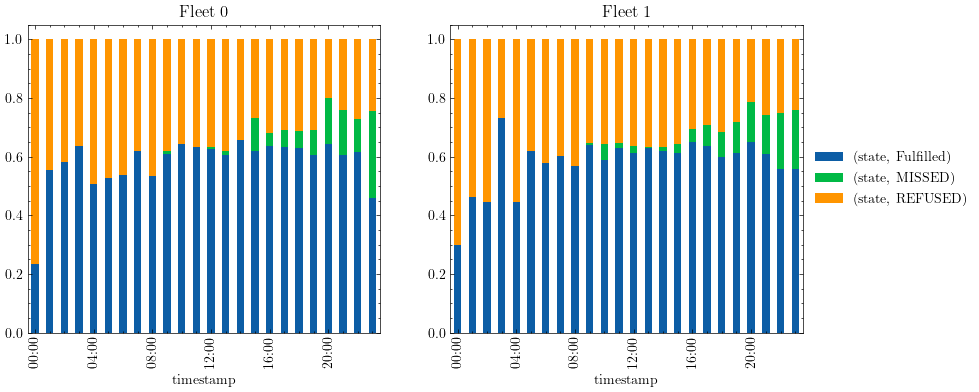

In [96]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

transactions_fleet_0_resampled.plot(kind = 'bar', stacked=True, ax=ax[0], legend=False)
transactions_fleet_1_resampled.plot(kind = 'bar', stacked=True, ax=ax[1], legend=True)

ax[1].legend(loc='center left', bbox_to_anchor=(1.0, 0.5))

ax[0].set_title('Fleet 0')
ax[1].set_title('Fleet 1')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=8))
    # a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

(0.0, 1.0)

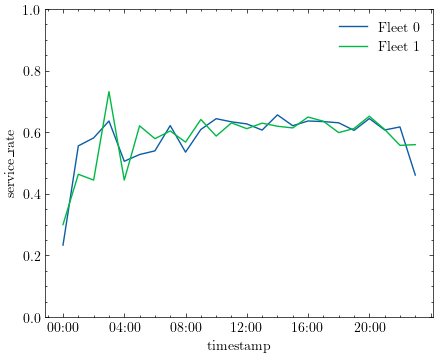

In [97]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5, 4))

transactions_fleet_0_resampled['service_rate'] = transactions_fleet_0_resampled[('state', 'Fulfilled')]
transactions_fleet_1_resampled['service_rate'] = transactions_fleet_1_resampled[('state', 'Fulfilled')]

# service_rate_mean = transactions_fleet_0_resampled.reset_index()[['timestamp', 'service_rate']].join(transactions_fleet_1_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')

sns.lineplot(data=transactions_fleet_0_resampled, x = transactions_fleet_0_resampled.index, y = 'service_rate', label='Fleet 0', ax=ax)
sns.lineplot(data=transactions_fleet_1_resampled, x = transactions_fleet_1_resampled.index, y = 'service_rate', label='Fleet 1', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
# ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

ax.set_ylim(0, 1.0)

### Vehilce Distance Travelled: Service vs. Operations

In [98]:
vehicle_tracking['fleet_vdt'] = vehicle_tracking['_vdt'].apply(lambda x: sum(eval(x)))

In [99]:
service_vdt_fleet_0 = transactions_fleet_0[transactions_fleet_0['state'] == 'Fulfilled'].resample(RESAMPLE_RATE, on = 'timestamp').agg({'distance': 'sum'})
service_vdt_fleet_1 = transactions_fleet_1[transactions_fleet_1['state'] == 'Fulfilled'].resample(RESAMPLE_RATE, on = 'timestamp').agg({'distance': 'sum'})

In [100]:
service_vdt_fleet_0['cumsum'] = service_vdt_fleet_0.cumsum()
service_vdt_fleet_1['cumsum'] = service_vdt_fleet_1.cumsum()

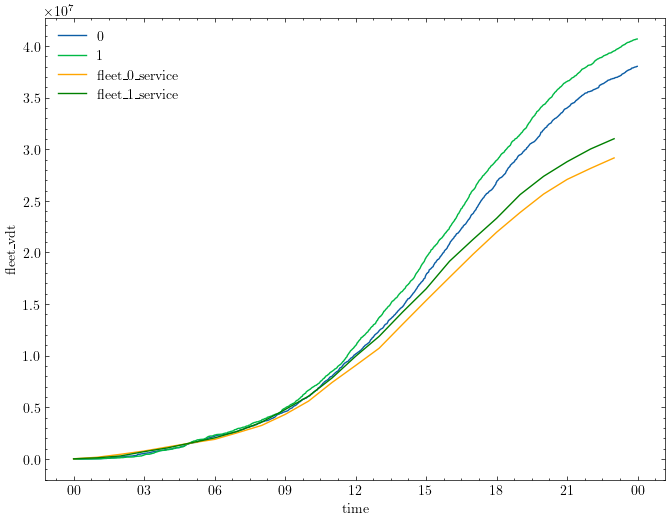

In [101]:
fig, ax = plt.subplots(1,1, figsize=(8, 6))

sns.lineplot(data=vehicle_tracking, x='time', y='fleet_vdt', hue='_fleet', ax=ax)
sns.lineplot(data=service_vdt_fleet_0, x='timestamp', y='cumsum', color='orange', label='fleet_0_service', ax=ax)
sns.lineplot(data=service_vdt_fleet_1, x='timestamp', y='cumsum', color='green', label='fleet_1_service', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

In [102]:
# share of operations VDT (excl customer serving)
hourly_vdt = vehicle_tracking.groupby('_fleet').resample(RESAMPLE_RATE, on = 'time').agg({'fleet_vdt': 'max'}).unstack(level=0).rename(columns={0: 'fleet_0_vdt_cumsum', 1: 'fleet_1_vdt_cumsum'}).droplevel(0, axis=1)

In [103]:
hourly_vdt = hourly_vdt.join(service_vdt_fleet_0)

hourly_vdt = hourly_vdt.join(service_vdt_fleet_1, rsuffix='_service_fleet_1')

hourly_vdt.rename(columns={'distance': 'distance_service_fleet_0', 'cumsum': 'cumsum_service_fleet_0'}, inplace=True)

hourly_vdt['fleet_0_ratio_of_empty_vdt'] = (hourly_vdt['fleet_0_vdt_cumsum'] - hourly_vdt['cumsum_service_fleet_0']) / hourly_vdt['fleet_0_vdt_cumsum']

hourly_vdt['fleet_1_ratio_of_empty_vdt'] = (hourly_vdt['fleet_1_vdt_cumsum'] - hourly_vdt['cumsum_service_fleet_1']) / hourly_vdt['fleet_1_vdt_cumsum']

In [104]:
hourly_vdt['fleet_0_vdt'] = hourly_vdt['fleet_0_vdt_cumsum'].diff().fillna(hourly_vdt['fleet_0_vdt_cumsum'].iloc[0])

hourly_vdt['fleet_1_vdt'] = hourly_vdt['fleet_1_vdt_cumsum'].diff().fillna(hourly_vdt['fleet_1_vdt_cumsum'].iloc[0])


In [105]:
hourly_vdt['fleet_0_ratio_of_empty_vdt'] = (hourly_vdt['fleet_0_vdt'] - hourly_vdt['distance_service_fleet_0']) / hourly_vdt['fleet_0_vdt']

hourly_vdt['fleet_1_ratio_of_empty_vdt'] = (hourly_vdt['fleet_1_vdt'] - hourly_vdt['distance_service_fleet_1']) / hourly_vdt['fleet_1_vdt']

In [106]:
hourly_vdt.head()

,fleet_0_vdt_cumsum,fleet_1_vdt_cumsum,distance_service_fleet_0,cumsum_service_fleet_0,distance_service_fleet_1,cumsum_service_fleet_1,fleet_0_ratio_of_empty_vdt,fleet_1_ratio_of_empty_vdt,fleet_0_vdt,fleet_1_vdt
time,,,,,,,,,,
1900-01-01 00:00:00,3.004827e+04,2.092815e+04,20905.836446,2.090584e+04,15578.807952,1.557881e+04,0.304258,0.255605,30048.266429,20928.146377
1900-01-01 01:00:00,1.856968e+05,1.114136e+05,145461.615305,1.663675e+05,97702.094585,1.132809e+05,0.065448,-0.079755,155648.493214,90485.444405
1900-01-01 02:00:00,5.185403e+05,3.800776e+05,287900.952379,4.542684e+05,180154.347601,2.934353e+05,0.135026,0.329444,332843.526521,268664.008886
1900-01-01 03:00:00,9.323133e+05,8.898292e+05,317430.826982,7.716992e+05,416459.700399,7.098950e+05,0.232838,0.183014,413772.975110,509751.566274
1900-01-01 04:00:00,1.528629e+06,1.595224e+06,394207.293554,1.165907e+06,364340.345234,1.074235e+06,0.338929,0.483494,596315.867235,705394.573866


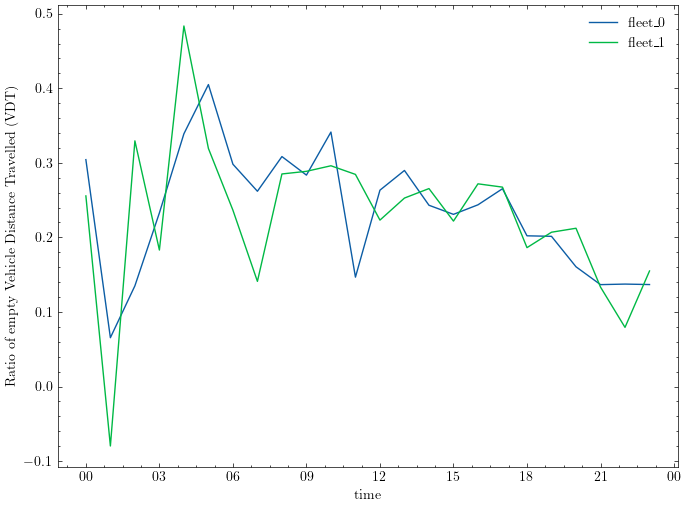

In [107]:
fig, ax = plt.subplots(1,1, figsize=(8, 6))

sns.lineplot(data=hourly_vdt, x='time', y='fleet_0_ratio_of_empty_vdt', label='fleet_0', ax=ax)
sns.lineplot(data=hourly_vdt, x='time', y='fleet_1_ratio_of_empty_vdt', label='fleet_1', ax=ax)

ax.set_ylabel('Ratio of empty Vehicle Distance Travelled (VDT)')

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

## Service Tasks

In [108]:
task_transactions_fleet_0 = pd.read_csv("data/output/transactions/fleet_0_task_transactions.csv")

task_transactions_fleet_1 = pd.read_csv("data/output/transactions/fleet_1_task_transactions.csv")

In [109]:
task_transactions_fleet_0['timestamp'] = task_transactions_fleet_0['start_time'].apply(SimulationTimeConverter.as_time)
task_transactions_fleet_0['timestamp'] = pd.to_datetime(task_transactions_fleet_0['timestamp'], format="%H:%M:%S")

task_transactions_fleet_1['timestamp'] = task_transactions_fleet_1['start_time'].apply(SimulationTimeConverter.as_time)
task_transactions_fleet_1['timestamp'] = pd.to_datetime(task_transactions_fleet_1['timestamp'], format="%H:%M:%S")

task_transactions_fleet_0['duration'] = task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['start_time']

task_transactions_fleet_1['duration'] = task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['start_time']

!! probably we should sanity-check why duration < waiting_time + charging_duration

In [110]:
task_transactions_fleet_0

,start_time,end_time,vehicle,state,fleet,charging_station,waiting_time,charging_duration,kWh_charged,timestamp,duration
0,106,147.154730,6,TaskState.FINISHED,0,872664c1affffff,6.381589,33.536319,27.946932,1900-01-01 01:46:00,41.154730
1,106,161.614478,8,TaskState.FINISHED,0,872664c1affffff,6.498671,33.113149,27.594291,1900-01-01 01:46:00,55.614478
2,121,173.163606,72,TaskState.FINISHED,0,872664c13ffffff,7.685428,30.849034,25.707528,1900-01-01 02:01:00,52.163606
3,121,174.499386,7,TaskState.FINISHED,0,872664c13ffffff,9.244035,33.743420,28.119517,1900-01-01 02:01:00,53.499386
4,121,178.141350,2,TaskState.FINISHED,0,872664c13ffffff,5.323220,33.464570,27.887142,1900-01-01 02:01:00,57.141350
...,...,...,...,...,...,...,...,...,...,...,...
466,1381,1440.000000,485,TaskState.EXECUTING_CHARGING,0,872664c1affffff,-35.777807,24.222193,20.185160,1900-01-01 23:01:00,59.000000
467,1381,1440.000000,486,TaskState.EXECUTING_RELOCATION,0,872664c1affffff,NaN,NaN,NaN,1900-01-01 23:01:00,59.000000
468,1381,1440.000000,488,TaskState.EXECUTING_CHARGING,0,872664cf5ffffff,-57.466603,2.533397,2.111164,1900-01-01 23:01:00,59.000000
469,1396,1440.000000,493,TaskState.EXECUTING_CHARGING,0,872664c1affffff,-34.145380,25.854620,21.545516,1900-01-01 23:16:00,44.000000


In [111]:
display(task_transactions_fleet_0.value_counts(subset=['state']))
display(task_transactions_fleet_1.value_counts(subset=['state']))

state                         
TaskState.FINISHED                458
TaskState.EXECUTING_CHARGING       10
TaskState.EXECUTING_RELOCATION      3
Name: count, dtype: int64

state                         
TaskState.FINISHED                483
TaskState.EXECUTING_CHARGING        8
TaskState.EXECUTING_RELOCATION      3
Name: count, dtype: int64

<Axes: xlabel='charging_duration', ylabel='kWh_charged'>

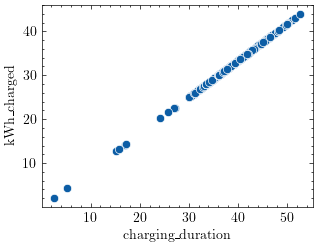

In [112]:
# check linearity
sns.scatterplot(data=task_transactions_fleet_0, x='charging_duration', y='kWh_charged')

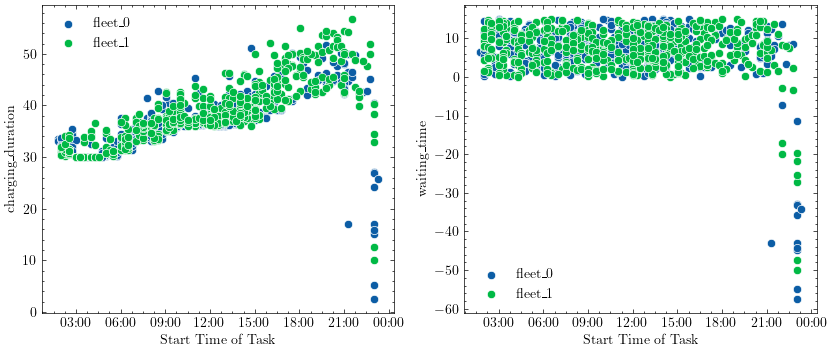

In [113]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

sns.scatterplot(data=task_transactions_fleet_0, x='timestamp', y='charging_duration', label='fleet_0', ax=ax[0])
sns.scatterplot(data=task_transactions_fleet_1, x='timestamp', y='charging_duration', label='fleet_1', ax=ax[0])

sns.scatterplot(data=task_transactions_fleet_0, x='timestamp', y='waiting_time', label='fleet_0', ax=ax[1])
sns.scatterplot(data=task_transactions_fleet_1, x='timestamp', y='waiting_time', label='fleet_1', ax=ax[1])

for a in ax:
    a.set_xlabel('Start Time of Task')
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

In [114]:
hourly_tasks = pd.merge(
    task_transactions_fleet_0.resample('h', on='timestamp').agg({'fleet': 'count', 'waiting_time': 'mean', 'charging_duration': 'mean'}).rename(columns={'fleet': 'tasks_finished_fleet_0', 'waiting_time': 'avg_waiting_time_fleet_0', 'charging_duration': 'avg_charging_duration_fleet_0'}),
    task_transactions_fleet_1.resample('h', on='timestamp').agg({'fleet': 'count', 'waiting_time': 'mean', 'charging_duration': 'mean'}).rename(columns={'fleet': 'tasks_finished_fleet_1', 'waiting_time': 'avg_waiting_time_fleet_1', 'charging_duration': 'avg_charging_duration_fleet_1'}),
    how='outer',
    left_index=True,
    right_index=True
).fillna(0)

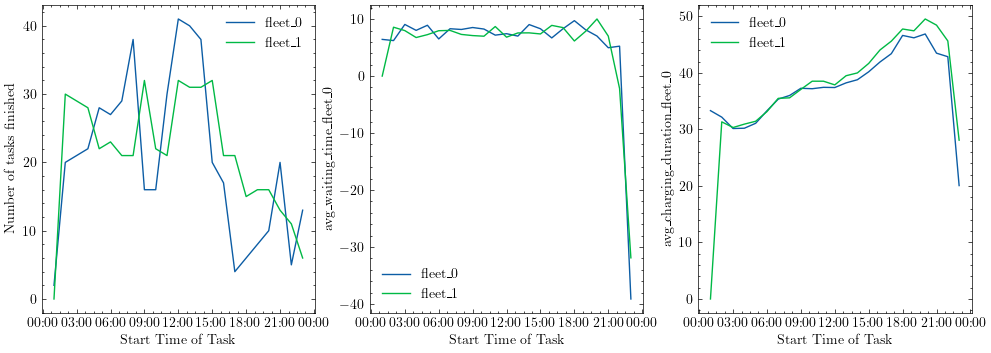

In [115]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(12, 4))

sns.lineplot(data=hourly_tasks, x='timestamp', y='tasks_finished_fleet_0', label='fleet_0', ax=ax[0])
sns.lineplot(data=hourly_tasks, x='timestamp', y='tasks_finished_fleet_1', label='fleet_1', ax=ax[0])

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_0', label='fleet_0', ax=ax[1])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_1', label='fleet_1', ax=ax[1])

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_charging_duration_fleet_0', label='fleet_0', ax=ax[2])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_charging_duration_fleet_1', label='fleet_1', ax=ax[2])

ax[0].set_ylabel("Number of tasks finished")

for a in ax:
    a.set_xlabel('Start Time of Task')
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

In [116]:
date_range = range(0,1440,15)

hourly_events_fleet_0 = pd.DataFrame({'time': date_range, 'events_ongoing_fleet_0': [((task_transactions_fleet_0['start_time'] <= i) & (task_transactions_fleet_0['end_time'] > i)).sum() for i in date_range]})
hourly_events_fleet_0.set_index('time', inplace=True)

hourly_events_fleet_1 = pd.DataFrame({'time': date_range, 'events_ongoing_fleet_1': [((task_transactions_fleet_1['start_time'] <= i) & (task_transactions_fleet_1['end_time'] > i)).sum() for i in date_range]})
hourly_events_fleet_1.set_index('time', inplace=True)

hourly_events_ongoing = pd.merge(
    hourly_events_fleet_0,
    hourly_events_fleet_1,
    how='outer',
    left_index=True,
    right_index=True
).fillna(0)

hourly_events_ongoing.reset_index(inplace=True)

In [117]:
hourly_events_ongoing['timestamp'] = hourly_events_ongoing['time'].apply(SimulationTimeConverter.as_time)
hourly_events_ongoing['timestamp'] = pd.to_datetime(hourly_events_ongoing['timestamp'], format="%H:%M:%S")

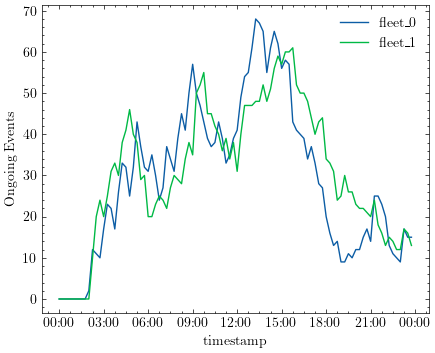

In [118]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5, 4))

sns.lineplot(data=hourly_events_ongoing, x='timestamp', y='events_ongoing_fleet_0', label='fleet_0', ax=ax)
sns.lineplot(data=hourly_events_ongoing, x='timestamp', y='events_ongoing_fleet_1', label='fleet_1', ax=ax)

ax.set_ylabel('Ongoing Events')

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))


In [119]:
task_transactions_fleet_0['timeslot'] = (task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['charging_duration']) - ((task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['charging_duration']) % 15)

task_transactions_fleet_1['timeslot'] = (task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['charging_duration']) - ((task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['charging_duration']) % 15)

In [120]:
tasks_incl_price = pd.concat(
    [task_transactions_fleet_0,task_transactions_fleet_1]
    ).merge(
        auction_tracking[['time', '_result.clearing_price']], 
        how='left', 
        left_on = 'timeslot', 
        right_on = "time"
        )

In [121]:
kWh_price = parser.getfloat("AUTONOMOUS_CAR", "CHARGING_COST_PER_KWH")

tasks_incl_price['charging_cost'] = tasks_incl_price['kWh_charged'] * kWh_price

In [122]:
tasks_incl_price.head()

,start_time,end_time,vehicle,state,fleet,charging_station,waiting_time,charging_duration,kWh_charged,timestamp,duration,timeslot,time,_result.clearing_price,charging_cost
0,106,147.154730,6,TaskState.FINISHED,0,872664c1affffff,6.381589,33.536319,27.946932,1900-01-01 01:46:00,41.154730,105.0,105.0,0.0,12.017181
1,106,161.614478,8,TaskState.FINISHED,0,872664c1affffff,6.498671,33.113149,27.594291,1900-01-01 01:46:00,55.614478,120.0,120.0,0.0,11.865545
2,106,161.614478,8,TaskState.FINISHED,0,872664c1affffff,6.498671,33.113149,27.594291,1900-01-01 01:46:00,55.614478,120.0,120.0,0.0,11.865545
3,121,173.163606,72,TaskState.FINISHED,0,872664c13ffffff,7.685428,30.849034,25.707528,1900-01-01 02:01:00,52.163606,135.0,135.0,0.0,11.054237
4,121,174.499386,7,TaskState.FINISHED,0,872664c13ffffff,9.244035,33.743420,28.119517,1900-01-01 02:01:00,53.499386,135.0,135.0,0.0,12.091392


In [123]:
hourly_costs = tasks_incl_price.groupby('fleet').resample('1h', on='timestamp').agg({'charging_cost': 'sum', '_result.clearing_price': 'sum'}).reset_index()
hourly_costs.rename(columns={'_result.clearing_price': 'reservation_cost'}, inplace=True)

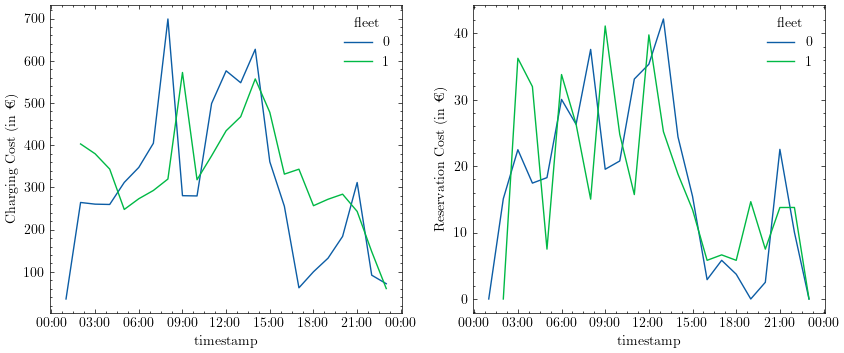

In [124]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

sns.lineplot(hourly_costs, x='timestamp', y='charging_cost', hue='fleet', ax=ax[0])
sns.lineplot(hourly_costs, x='timestamp', y='reservation_cost', hue='fleet', ax=ax[1])

ax[0].set_ylabel('Charging Cost (in €)')
ax[1].set_ylabel('Reservation Cost (in €)')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

### other stuff

<Axes: xlabel='waiting_time', ylabel='pick_up_time'>

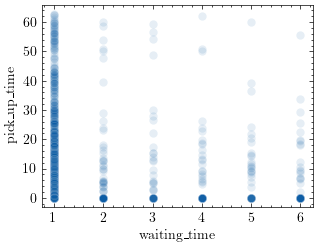

In [68]:
sns.scatterplot(transactions_fleet_0, x='waiting_time', y='pick_up_time', alpha=.1)

In [69]:
transactions_fleet_0['pick_up_time'].describe()

count    6551.000000
mean        4.126147
std         8.132946
min         0.000000
25%         0.000000
50%         1.278793
75%         4.707706
max        62.776211
Name: pick_up_time, dtype: float64